In [1]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.14.0+cu126
True


In [ ]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

train_dir = Path("../data/raw/train/train_images")
json_path = Path("../data/raw/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")

# 1. Load JSON
with open(json_path, "r") as f:
    coco = json.load(f)

# 2. Group annotations 
# ponytail: Using dict.setdefault implicitly deduplicates the messy JSON records we found earlier.
ann_dict = {}
for ann in coco["annotations"]:
    ann_dict.setdefault(ann["image_id"], []).append(ann)

# 3. Visualize first annotated sample to prove pipeline sanity
sample_img_id = next(iter(ann_dict.keys()))
sample_filename = next(img["file_name"] for img in coco["images"] if img["id"] == sample_img_id)

image = cv2.imread(str(train_dir / sample_filename), cv2.IMREAD_GRAYSCALE)
mask = np.zeros_like(image, dtype=np.uint8)

for ann in ann_dict.get(sample_img_id, []):
    for poly in ann.get("segmentation", []):
        poly_pts = np.round(np.array(poly, dtype=np.float32).reshape(-1, 2)).astype(np.int32)
        cv2.fillPoly(mask, [poly_pts], 1)

# 4. Render
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
ax1.imshow(image, cmap='gray'); ax1.axis('off')
ax1.set_title(f"Original Image: {sample_filename}\nResolution: {image.shape}")

ax2.imshow(mask, cmap='magma'); ax2.axis('off')
ax2.set_title(f"Binary Mask\nForeground pixels: {mask.sum()}")

plt.tight_layout()
plt.show()

In [32]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm

# 1. Minimal Zero-Dependency U-Net
class LeanUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # ponytail: Naive plain convolutions. 
        # Upgrade path: MORDEN's 5x5 kernels + InstanceNorm for Phase 2.
        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True)
            )
        
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        
        self.pool = nn.MaxPool2d(2, 2)
        
        self.bot = conv_block(64, 128)
        
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = conv_block(128, 64) # 128 because of skip connection
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = conv_block(32, 16)
        
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        
        b = self.bot(self.pool(e3))
        
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        
        return self.out(d1) # Returns raw logits

# 2. Loss & Metrics
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce_weight = bce_weight
        self.bce = nn.BCEWithLogitsLoss()
        
    def forward(self, logits, targets, smooth=1.0):
        bce_loss = self.bce(logits, targets)
        
        # Dice Loss
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum(dim=(2,3))
        union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))
        dice_loss = 1.0 - (2. * intersection + smooth) / (union + smooth)
        
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss.mean()

def calculate_iou(logits, targets, threshold=0.5, eps=1e-6):
    preds = (torch.sigmoid(logits) > threshold).float()
    intersection = (preds * targets).sum(dim=(2,3))
    union = (preds + targets).sum(dim=(2,3)) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()

/home/virendra2605/Documents/inter-iit-cvps/task-a-solar-fragments/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [33]:
# Hyperparameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 8
epochs = 3 

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

model = LeanUNet().to(device)
criterion = BCEDiceLoss().to(device)
optimizer = AdamW(model.parameters(), lr=1e-3)

print(f"Starting Baseline Training on {device}...")

for epoch in range(epochs):
    model.train()
    train_loss, train_iou = 0.0, 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
    for images, masks in pbar:
        images, masks = images.to(device), masks.to(device)
        
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        train_iou += calculate_iou(logits, masks)
        
        pbar.set_postfix(loss=loss.item())
        
    # Validation
    model.eval()
    val_loss, val_iou = 0.0, 0.0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]"):
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            val_loss += criterion(logits, masks).item()
            val_iou += calculate_iou(logits, masks)
            
    print(f"Epoch {epoch+1} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f} | Val IoU: {val_iou/len(val_loader):.4f}")

Starting Baseline Training on cuda...


Epoch 1/3 [Val]: 100%|██████████| 29/29 [00:03<00:00,  9.31it/s]


Epoch 1 | Train Loss: 0.6628 | Val Loss: 0.5987 | Val IoU: 0.0000


Epoch 2/3 [Val]: 100%|██████████| 29/29 [00:03<00:00,  9.33it/s]


Epoch 2 | Train Loss: 0.5651 | Val Loss: 0.5388 | Val IoU: 0.0000


Epoch 3/3 [Val]: 100%|██████████| 29/29 [00:02<00:00, 11.00it/s]


Epoch 3 | Train Loss: 0.4976 | Val Loss: 0.4678 | Val IoU: 0.3139


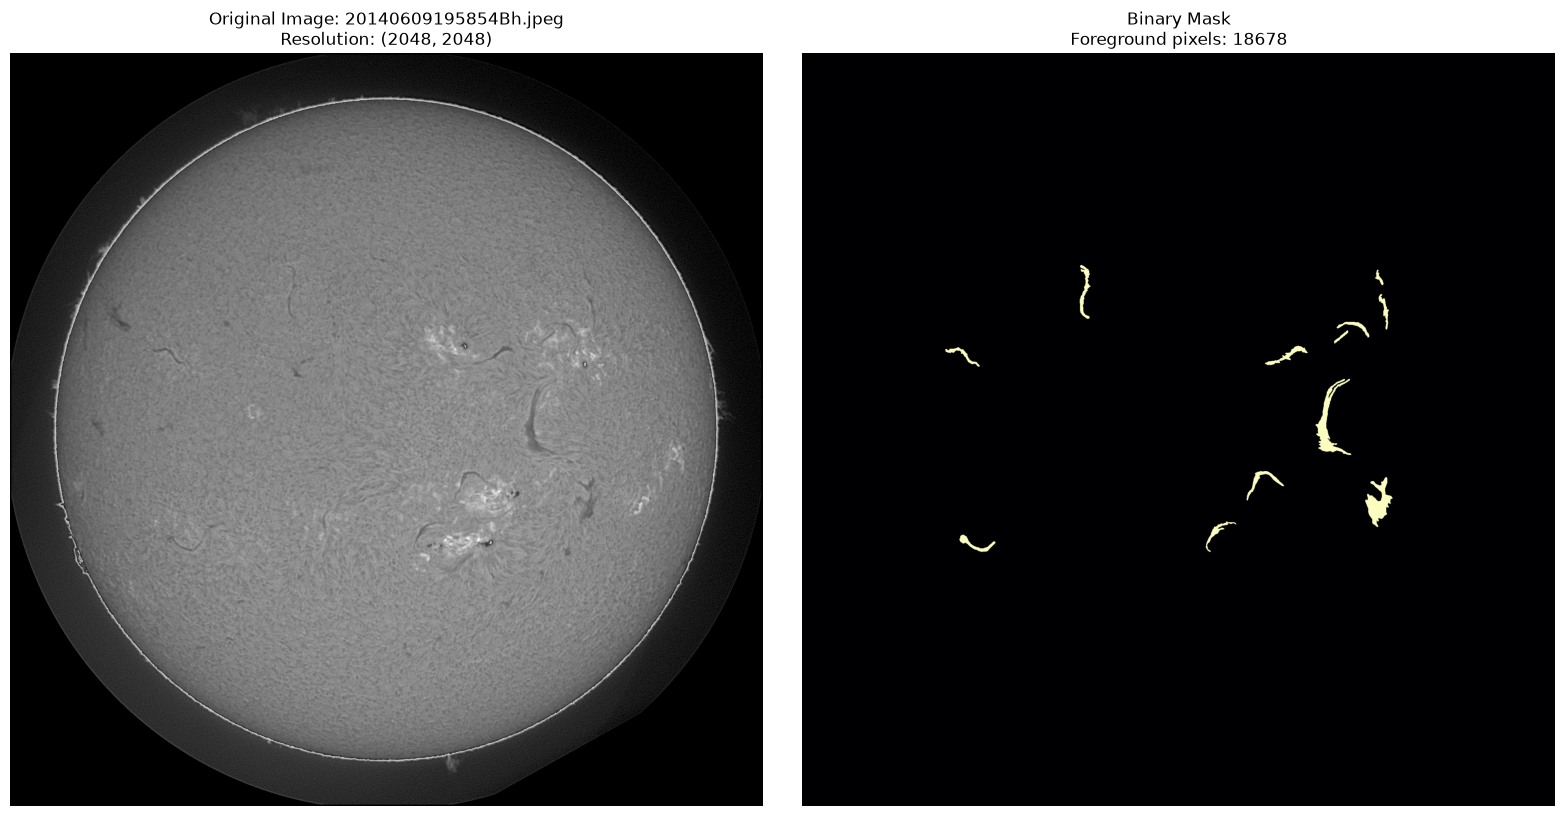

In [34]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Paths
train_dir = Path("../data/raw/train/train_images")
json_path = Path("../data/raw/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")

# 2. Load JSON
with open(json_path, "r") as f:
    coco = json.load(f)

# 3. Group annotations by image_id
ann_dict = {}
for ann in coco["annotations"]:
    ann_dict.setdefault(ann["image_id"], []).append(ann)

# Pick the first annotated image_id from the dictionary
sample_img_id = next(iter(ann_dict.keys()))
sample_filename = next(img["file_name"] for img in coco["images"] if img["id"] == sample_img_id)
img_path = str(train_dir / sample_filename)

# 4. Load Image
image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# 5. Build Mask
mask = np.zeros_like(image, dtype=np.uint8)
for ann in ann_dict.get(sample_img_id, []):
    for poly in ann.get("segmentation", []):
        poly_pts = np.array(poly, dtype=np.float32).reshape(-1, 2)
        poly_pts = np.round(poly_pts).astype(np.int32)
        cv2.fillPoly(mask, [poly_pts], 1)

# 6. Visualize
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title(f"Original Image: {sample_filename}\nResolution: {image.shape}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='magma')
plt.title(f"Binary Mask\nForeground pixels: {mask.sum()}")
plt.axis('off')

plt.tight_layout()
plt.show()